# 01. Analisis Tren Kunjungan dan Revenue, Klinik Medinara

**Pertanyaan bisnis 1:** bagaimana tren kunjungan dan pendapatan per bulan, kapan puncaknya, dan hari serta jam apa yang paling ramai?

**Definisi**
- *Kunjungan* = appointment berstatus `completed`
- *Revenue* = tarif nominal appointment `completed` (`revenue_idr`), bukan pendapatan riil

**Peringatan data:** Juni 2021 hanya mulai 4 Juni, dan data berhenti 31 Januari 2025. Tahun 2021 dan 2025 adalah tahun parsial, jadi perbandingan antar tahun memakai rata-rata per bulan.

**Versi Google Colab / tanpa database.** Notebook ini membaca dua file CSV hasil ekspor dari PostgreSQL, jadi tidak perlu koneksi ke database.

**Prasyarat:** file `monthly_trend.csv` (query Q9) dan `hari_jam.csv` (query ekspor hari × jam) sudah kamu ekspor dari pgAdmin.

In [1]:
import os, io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

FIG_DIR = Path("reports/figures");  FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = Path("data/processed");   OUT_DIR.mkdir(parents=True, exist_ok=True)

def simpan(fig, nama):
    fig.savefig(FIG_DIR / nama, bbox_inches="tight", dpi=150)
    print("Tersimpan:", FIG_DIR / nama)

## 1. Muat file CSV

Jalankan sel di bawah, lalu pilih **dua file** saat jendela unggah muncul:
- `monthly_trend.csv`
- `hari_jam.csv`

Pembacaan file otomatis mengenali pemisah koma atau titik koma, dan tanggal berformat `2021-06-01` maupun `01/06/2021`.

In [4]:
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    uploaded = files.upload()          # pilih monthly_trend.csv dan hari_jam.csv
    print("File terunggah:", list(uploaded))

def baca_csv(nama):
    """Baca CSV dengan pemisah koma atau titik koma (deteksi otomatis)."""
    df = pd.read_csv(nama, sep=None, engine="python", encoding="utf-8-sig")
    df.columns = [c.strip() for c in df.columns]
    return df

def parse_tanggal(seri):
    """Terima format 2021-06-01 (ISO) atau 01/06/2021 (hari/bulan/tahun)."""
    s = seri.astype(str).str.strip()
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    dmy = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    hasil = iso.fillna(dmy)
    assert hasil.notna().all(), "Ada tanggal yang tidak terbaca. Periksa format kolom bulan."
    return hasil

Saving hari_jam.csv to hari_jam (1).csv
Saving monthly_trend.csv to monthly_trend.csv
File terunggah: ['hari_jam (1).csv', 'monthly_trend.csv']


## 2. Data bulanan

Dibaca dari `monthly_trend.csv` (hasil query Q9), lalu ditambah kolom turunan di pandas.

In [5]:
m = baca_csv("monthly_trend.csv")
m["appt_month"] = parse_tanggal(m.pop("bulan"))
m = m.sort_values("appt_month").reset_index(drop=True)

m["tahun"] = m["appt_month"].dt.year
m["rata_per_kunjungan"] = m["revenue_idr"] / m["kunjungan"]
m["ma3_kunjungan"] = m["kunjungan"].rolling(3).mean()
m["mom_kunjungan_pct"] = m["kunjungan"].pct_change() * 100
m["yoy_kunjungan_pct"] = m["kunjungan"].pct_change(12) * 100
m["yoy_revenue_pct"] = m["revenue_idr"].pct_change(12) * 100

print(m.shape)
m.head()

(44, 13)


,total_appt,kunjungan,cancelled,no_show,rescheduled,revenue_idr,appt_month,tahun,rata_per_kunjungan,ma3_kunjungan,mom_kunjungan_pct,yoy_kunjungan_pct,yoy_revenue_pct
0,14,10,1,2,1,1850000,2021-06-01,2021,"185,000.0",NaN,NaN,NaN,NaN
1,15,13,1,1,0,2150000,2021-07-01,2021,"165,384.6",NaN,30.0,NaN,NaN
2,23,19,2,1,1,3435000,2021-08-01,2021,"180,789.5",14.0,46.2,NaN,NaN
3,33,27,1,3,2,4515000,2021-09-01,2021,"167,222.2",19.7,42.1,NaN,NaN
4,31,27,1,2,1,4725000,2021-10-01,2021,"175,000.0",24.3,0.0,NaN,NaN


### Cek kesesuaian dengan SQL

Total ini harus sama dengan hasil verifikasi V9 dan V10 di `02b_verify_clean_data.sql`.

In [6]:
total_kunjungan = int(m["kunjungan"].sum())
total_revenue = int(m["revenue_idr"].sum())
print(f"Total kunjungan : {total_kunjungan:,}   (harapan 4.000)")
print(f"Total revenue   : Rp {total_revenue:,}   (harapan Rp 736.435.000)")
assert total_kunjungan == 4000, "Total kunjungan tidak cocok, periksa 02_cleaning.sql"
assert total_revenue == 736_435_000, "Total revenue tidak cocok, periksa 02_cleaning.sql"
print("OK: cocok dengan SQL")

Total kunjungan : 4,000   (harapan 4.000)
Total revenue   : Rp 736,435,000   (harapan Rp 736.435.000)
OK: cocok dengan SQL


## 3. Tren kunjungan bulanan

Tersimpan: reports/figures/01_tren_kunjungan.png


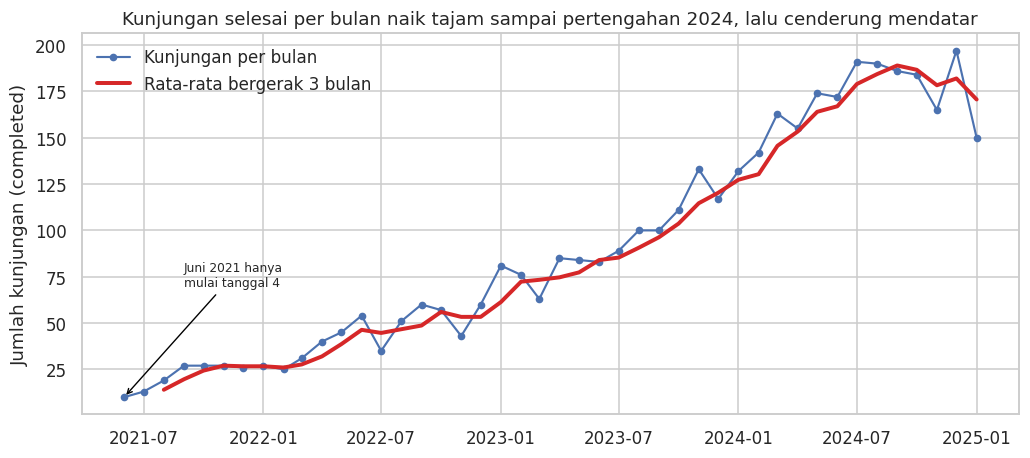

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(m["appt_month"], m["kunjungan"], marker="o", ms=4, lw=1.4, label="Kunjungan per bulan")
ax.plot(m["appt_month"], m["ma3_kunjungan"], lw=2.6, color="#d62728", label="Rata-rata bergerak 3 bulan")
ax.annotate("Juni 2021 hanya\nmulai tanggal 4", xy=(m["appt_month"].iloc[0], m["kunjungan"].iloc[0]),
            xytext=(m["appt_month"].iloc[3], 70), fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.9, color="black"))
ax.set_title("Kunjungan selesai per bulan naik tajam sampai pertengahan 2024, lalu cenderung mendatar")
ax.set_xlabel(""); ax.set_ylabel("Jumlah kunjungan (completed)")
ax.legend(frameon=False)
simpan(fig, "01_tren_kunjungan.png"); plt.show()

## 4. Revenue bulanan

Tersimpan: reports/figures/02_revenue_bulanan.png


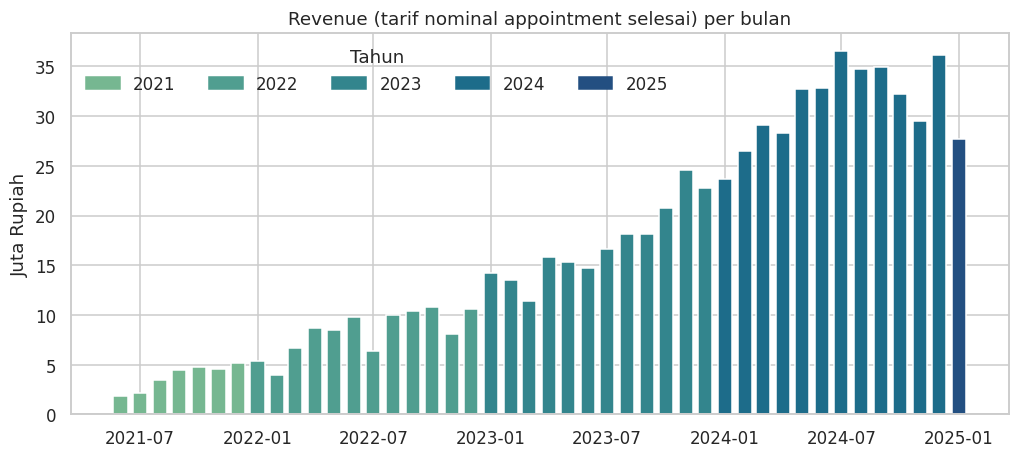

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.5))
warna = dict(zip(sorted(m["tahun"].unique()), sns.color_palette("crest", m["tahun"].nunique())))
ax.bar(m["appt_month"], m["revenue_idr"] / 1e6, width=22, color=m["tahun"].map(warna))
ax.set_title("Revenue (tarif nominal appointment selesai) per bulan")
ax.set_ylabel("Juta Rupiah"); ax.set_xlabel("")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in warna.values()]
ax.legend(handles, [str(t) for t in warna], title="Tahun", frameon=False, ncol=5)
simpan(fig, "02_revenue_bulanan.png"); plt.show()

## 5. Perbandingan tahun lewat rata-rata per bulan

Tahun parsial (2021 = 7 bulan, 2025 = 1 bulan) tidak boleh dibandingkan lewat total.

In [9]:
tahunan = (m.groupby("tahun")
             .agg(jumlah_bulan=("appt_month", "count"),
                  total_kunjungan=("kunjungan", "sum"),
                  total_revenue=("revenue_idr", "sum"),
                  rata_kunjungan_per_bulan=("kunjungan", "mean"),
                  rata_revenue_per_bulan=("revenue_idr", "mean"))
             .reset_index())
tahunan["parsial"] = tahunan["jumlah_bulan"] < 12
tahunan["pertumbuhan_rata_kunjungan_pct"] = tahunan["rata_kunjungan_per_bulan"].pct_change() * 100
tahunan

,tahun,jumlah_bulan,total_kunjungan,total_revenue,rata_kunjungan_per_bulan,rata_revenue_per_bulan,parsial,pertumbuhan_rata_kunjungan_pct
0,2021,7,149,26430000,21.3,"3,775,714.3",True,NaN
1,2022,12,528,99390000,44.0,"8,282,500.0",False,106.7
2,2023,12,1122,206000000,93.5,"17,166,666.7",False,112.5
3,2024,12,2051,376955000,170.9,"31,412,916.7",False,82.8
4,2025,1,150,27660000,150.0,"27,660,000.0",True,-12.2


Tersimpan: reports/figures/03_rata_kunjungan_per_tahun.png


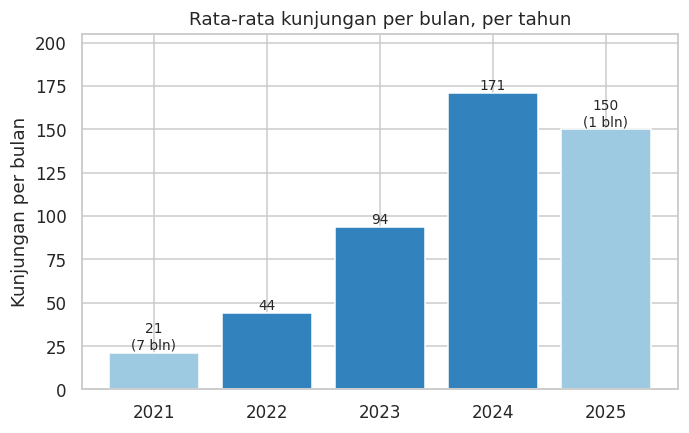

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(tahunan["tahun"].astype(str), tahunan["rata_kunjungan_per_bulan"],
              color=["#9ecae1" if p else "#3182bd" for p in tahunan["parsial"]])
for b, p, n in zip(bars, tahunan["parsial"], tahunan["jumlah_bulan"]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 2,
            f"{b.get_height():.0f}" + (f"\n({n} bln)" if p else ""), ha="center", fontsize=9)
ax.set_title("Rata-rata kunjungan per bulan, per tahun")
ax.set_ylabel("Kunjungan per bulan"); ax.set_xlabel("")
ax.set_ylim(0, tahunan["rata_kunjungan_per_bulan"].max() * 1.2)
simpan(fig, "03_rata_kunjungan_per_tahun.png"); plt.show()

## 6. Pertumbuhan year-over-year

Membandingkan setiap bulan dengan bulan yang sama tahun lalu sehingga pengaruh musiman ikut tersingkir. Persen pertumbuhan tahun 2022 sangat besar karena basisnya kecil (klinik baru mulai), jadi fokuskan pembacaan pada arah tren di 2023 dan 2024.

Tersimpan: reports/figures/04_pertumbuhan_yoy.png


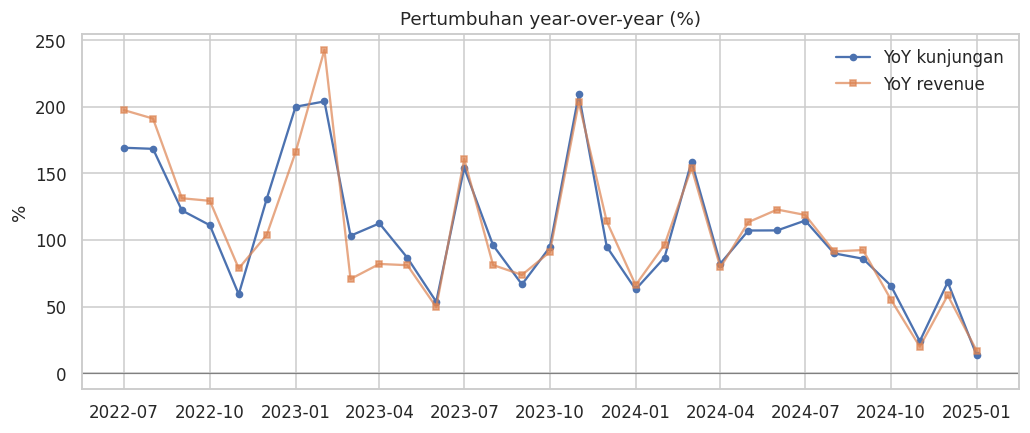

In [11]:
# Juni 2022 dikeluarkan: pembandingnya Juni 2021 yang tidak penuh dan sangat kecil, sehingga persennya menyesatkan
y = m.dropna(subset=["yoy_kunjungan_pct"]).query("appt_month > '2022-06-01'")
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(y["appt_month"], y["yoy_kunjungan_pct"], marker="o", ms=4, label="YoY kunjungan")
ax.plot(y["appt_month"], y["yoy_revenue_pct"], marker="s", ms=4, alpha=0.7, label="YoY revenue")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Pertumbuhan year-over-year (%)")
ax.set_ylabel("%"); ax.set_xlabel(""); ax.legend(frameon=False)
simpan(fig, "04_pertumbuhan_yoy.png"); plt.show()

## 7. Laju pertumbuhan: apakah melambat?

Regresi linear pada `log(kunjungan)` terhadap waktu. Kemiringannya dibaca sebagai **rata-rata pertumbuhan per bulan** (dalam persen). Juni 2021 dan Januari 2025 dikeluarkan karena tidak penuh atau berada di ujung data.

In [12]:
bulan_penuh = m[(m["appt_month"] >= "2021-07-01") & (m["appt_month"] <= "2024-12-01")].copy()

def laju_pertumbuhan(df):
    x = np.arange(len(df))
    r = stats.linregress(x, np.log(df["kunjungan"]))
    return pd.Series({"jumlah_bulan": len(df),
                      "pertumbuhan_per_bulan_pct": (np.exp(r.slope) - 1) * 100,
                      "r_kuadrat": r.rvalue ** 2})

hasil = pd.concat({"Seluruh periode": laju_pertumbuhan(bulan_penuh)}, axis=1).T
per_tahun = bulan_penuh.groupby("tahun").apply(laju_pertumbuhan)
hasil = pd.concat([hasil, per_tahun.rename(index=str)])
hasil.style.format({"jumlah_bulan": "{:.0f}", "pertumbuhan_per_bulan_pct": "{:.1f}", "r_kuadrat": "{:.2f}"})

/tmp/ipykernel_1246/1041286050.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_tahun = bulan_penuh.groupby("tahun").apply(laju_pertumbuhan)


,jumlah_bulan,pertumbuhan_per_bulan_pct,r_kuadrat
Seluruh periode,42,6.2,0.96
2021,6,13.8,0.65
2022,12,7.2,0.66
2023,12,5.2,0.79
2024,12,2.8,0.64


**Cara membaca:** semakin kecil persen pertumbuhan per bulan pada tahun berikutnya, semakin melambat pertumbuhannya. Tahun 2021 hanya punya 6 bulan penuh di sini (Juli sampai Desember), jadi angkanya kurang stabil dibanding tahun lain.

## 8. Bulan puncak

In [13]:
puncak = (m.assign(rank_revenue=m["revenue_idr"].rank(ascending=False, method="min").astype(int),
                   rank_kunjungan=m["kunjungan"].rank(ascending=False, method="min").astype(int))
            .query("rank_revenue <= 5 or rank_kunjungan <= 5")
            .sort_values("rank_revenue")
            [["appt_month", "kunjungan", "revenue_idr", "rank_revenue", "rank_kunjungan"]])
puncak

,appt_month,kunjungan,revenue_idr,rank_revenue,rank_kunjungan
37,2024-07-01,191,36485000,1,2
42,2024-12-01,197,36115000,2,1
39,2024-09-01,186,34945000,3,4
38,2024-08-01,190,34700000,4,3
36,2024-06-01,172,32805000,5,7
40,2024-10-01,184,32165000,7,5


## 9. Hari dan jam tersibuk

Tersimpan: reports/figures/05_heatmap_hari_jam.png


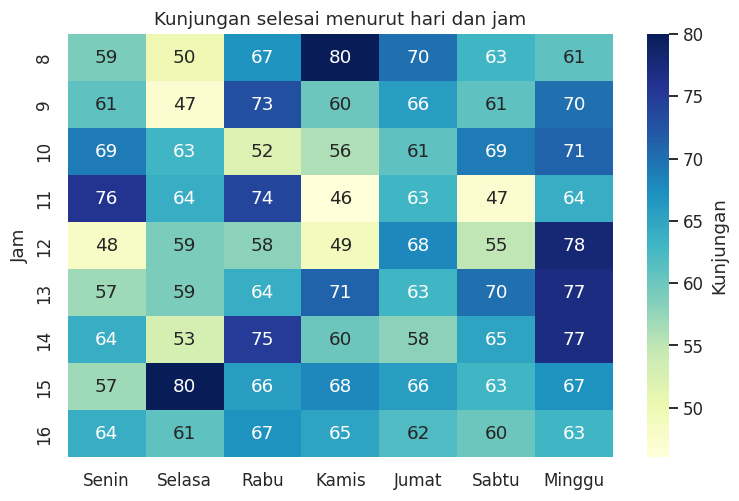

In [14]:
hj = baca_csv("hari_jam.csv")        # kolom: appt_dow, appt_hour, kunjungan
assert hj["kunjungan"].sum() == 4000, "Total kunjungan di hari_jam.csv harus 4.000"

nama_hari = {1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu", 7: "Minggu"}
pivot = (hj.pivot(index="appt_hour", columns="appt_dow", values="kunjungan")
           .rename(columns=nama_hari))
pivot.index.name = "Jam"

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={"label": "Kunjungan"}, ax=ax)
ax.set_title("Kunjungan selesai menurut hari dan jam")
ax.set_xlabel(""); ax.set_ylabel("Jam")
simpan(fig, "05_heatmap_hari_jam.png"); plt.show()

## 10. Apakah perbedaan antar hari dan jam berarti?

Selisih kecil bisa saja kebetulan. Uji **chi-square goodness-of-fit** memeriksa apakah sebaran kunjungan menyimpang dari sebaran yang diharapkan jika semua hari (atau jam) sama ramainya.

- **Hari:** harapan disesuaikan dengan jumlah tiap hari kalender dalam periode data, karena periode itu tidak memuat tiap hari dalam jumlah persis sama.
- **Jam:** harapan seragam di 9 jam praktik.
- **Cramér's V** mengukur *besar* penyimpangan (0 = tidak ada, makin besar makin kuat). Nilai p kecil dengan V mendekati 0 berarti ada perbedaan yang terdeteksi tetapi sangat kecil secara praktis.
- Tingkat signifikansi: 0,05.

In [15]:
ALPHA = 0.05

def uji_chi2(observasi, harapan_proporsi, label):
    obs = np.asarray(observasi, dtype=float)
    exp = np.asarray(harapan_proporsi, dtype=float) / np.sum(harapan_proporsi) * obs.sum()
    chi2, p = stats.chisquare(obs, exp)
    v = np.sqrt(chi2 / (obs.sum() * (len(obs) - 1)))
    print(f"{label}: chi2 = {chi2:.2f}, derajat bebas = {len(obs)-1}, p = {p:.4f}, Cramer's V = {v:.3f}")
    print("  ->", "ada perbedaan signifikan" if p < ALPHA else "TIDAK ada perbedaan signifikan",
          f"pada alpha {ALPHA}")
    return chi2, p, v

# --- Hari ---
# Rentang tanggal data (dari query V3 di 02b_verify_clean_data.sql)
TANGGAL_AWAL, TANGGAL_AKHIR = "2021-06-04", "2025-01-31"
semua_hari = pd.date_range(TANGGAL_AWAL, TANGGAL_AKHIR)
jumlah_per_dow = semua_hari.dayofweek.value_counts().sort_index()      # 0 = Senin
harapan_dow = jumlah_per_dow.values

obs_dow = hj.groupby("appt_dow")["kunjungan"].sum().sort_index().values  # 1 = Senin
res_hari = uji_chi2(obs_dow, harapan_dow, "Hari")

# --- Jam ---
obs_jam = hj.groupby("appt_hour")["kunjungan"].sum().sort_index().values
res_jam = uji_chi2(obs_jam, np.ones(len(obs_jam)), "Jam ")

Hari: chi2 = 10.41, derajat bebas = 6, p = 0.1084, Cramer's V = 0.021
  -> TIDAK ada perbedaan signifikan pada alpha 0.05
Jam : chi2 = 4.29, derajat bebas = 8, p = 0.8302, Cramer's V = 0.012
  -> TIDAK ada perbedaan signifikan pada alpha 0.05


**Catatan:** uji ini mengasumsikan setiap kunjungan independen. Jangan menafsirkannya sebagai bukti sebab-akibat. Kalau hasilnya tidak signifikan, tulis apa adanya di laporan: *tidak ada hari atau jam yang menonjol secara statistik*.

## 11. Ekspor tabel agregat

Tabel di bawah hanya berisi agregat (tanpa data pasien), jadi aman dipublikasikan di GitHub dan dipakai di dashboard.

In [16]:
bulanan_out = m[["appt_month", "total_appt", "kunjungan", "cancelled", "no_show", "rescheduled", "revenue_idr"]].rename(columns={"appt_month": "bulan"})
bulanan_out.to_csv(OUT_DIR / "monthly_trend.csv", index=False)

tahunan.to_csv(OUT_DIR / "yearly_summary.csv", index=False)

pivot.reset_index().to_csv(OUT_DIR / "heatmap_hari_jam.csv", index=False)

print("Tersimpan di", OUT_DIR.resolve())
for f in sorted(OUT_DIR.glob("*.csv")):
    print(" -", f.name)

Tersimpan di /content/data/processed
 - heatmap_hari_jam.csv
 - monthly_trend.csv
 - yearly_summary.csv


## 12. Ringkasan angka kunci untuk menulis temuan

In [17]:
bln_puncak_rev = m.loc[m["revenue_idr"].idxmax()]
bln_puncak_kjg = m.loc[m["kunjungan"].idxmax()]

print("RINGKASAN")
print("-" * 60)
print(f"Periode data          : {m['appt_month'].min():%b %Y} sampai {m['appt_month'].max():%b %Y} ({len(m)} bulan)")
print(f"Total kunjungan       : {total_kunjungan:,}")
print(f"Total revenue nominal : Rp {total_revenue:,}")
print(f"Puncak revenue        : {bln_puncak_rev['appt_month']:%b %Y} (Rp {bln_puncak_rev['revenue_idr']:,.0f})")
print(f"Puncak kunjungan      : {bln_puncak_kjg['appt_month']:%b %Y} ({bln_puncak_kjg['kunjungan']:.0f} kunjungan)")
print()
print("Rata-rata kunjungan per bulan, per tahun:")
for _, r in tahunan.iterrows():
    ket = f" ({int(r['jumlah_bulan'])} bulan, parsial)" if r["parsial"] else ""
    print(f"  {int(r['tahun'])}: {r['rata_kunjungan_per_bulan']:.1f}{ket}")
print()
print(f"Uji hari : p = {res_hari[1]:.4f}, V = {res_hari[2]:.3f}")
print(f"Uji jam  : p = {res_jam[1]:.4f}, V = {res_jam[2]:.3f}")

RINGKASAN
------------------------------------------------------------
Periode data          : Jun 2021 sampai Jan 2025 (44 bulan)
Total kunjungan       : 4,000
Total revenue nominal : Rp 736,435,000
Puncak revenue        : Jul 2024 (Rp 36,485,000)
Puncak kunjungan      : Dec 2024 (197 kunjungan)

Rata-rata kunjungan per bulan, per tahun:
  2021: 21.3 (7 bulan, parsial)
  2022: 44.0
  2023: 93.5
  2024: 170.9
  2025: 150.0 (1 bulan, parsial)

Uji hari : p = 0.1084, V = 0.021
Uji jam  : p = 0.8302, V = 0.012


## 13. Draf temuan (isi dengan kata-katamu sendiri)

Tulis 3 sampai 4 poin. Tiap poin berisi **angka, interpretasi, dan batasan**.

1. **Tren:** ...
2. **Laju pertumbuhan:** ... (melambat atau tidak? lihat bagian 6 dan 7)
3. **Puncak:** ... (sebutkan ukuran yang dipakai: revenue atau kunjungan)
4. **Hari dan jam:** ... (lihat hasil uji chi-square di bagian 10)

**Batasan yang selalu disebutkan:** revenue adalah tarif nominal, tahun 2021 dan 2025 parsial, dan data tampak sintetis.

## 14. Unduh hasil (khusus Colab)

File di Colab hilang saat sesi berakhir. Sel ini membuat satu file ZIP berisi grafik dan CSV agregat, lalu mengunduhnya ke komputermu.

In [18]:
import shutil
shutil.make_archive("hasil_analisis_tren", "zip", ".", "reports")
shutil.make_archive("hasil_csv_agregat", "zip", ".", "data")
if IN_COLAB:
    files.download("hasil_analisis_tren.zip")
    files.download("hasil_csv_agregat.zip")
else:
    print("Dibuat: hasil_analisis_tren.zip dan hasil_csv_agregat.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>